In [7]:
%load_ext autoreload
%autoreload 2

# Imports
import sys; sys.path.append("..")
import io, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pywt                                   # pip install PyWavelets
from PIL import Image
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from src.datos import DATA, a_gris
from src.preproceso import preprocesar, mascara_cerebral, normalizar, a_tamano_comun
from src.segmentacion import umbral_adaptativo
from src.caracteristicas import medidas_corte, glcm_features, region_profunda
from src.clasificacion_umbrales import (preparar, particion_por_grupo, ajustar_umbrales, aplicar_regla,
                                       metricas, REGLA, SEMILLA)

# scikit-image >= 0.26 avisa que el parámetro min_size de remove_small_objects va a cambiar de nombre
warnings.filterwarnings("ignore", category=FutureWarning)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 6.1 Cortes de prueba y regla de clasificación de referencia

In [8]:
# Mismos datos y grupos que el notebook 05. Se separa una partición de grupos completa (la 0 de las 5) como prueba:
# los umbrales de la regla (Area_rel O Entropia > percentil 95 de los controles) se fijan con las imágenes
# originales de las otras cuatro.
feat = pd.read_csv(Path("..") / "data" / "caracteristicas_cortes.csv")
datos = preparar(feat)
y = datos["y"].to_numpy()
part = particion_por_grupo(datos["Grupo"].to_numpy(), y)
tr, te = np.flatnonzero(part != 0), np.flatnonzero(part == 0)
umbrales = ajustar_umbrales(datos.iloc[tr])
print(f"Umbrales: {len(tr)} cortes | prueba: {len(te)} cortes")
assert not set(datos.loc[tr, "Grupo"]) & set(datos.loc[te, "Grupo"])
print({k: round(v, 4) for k, v in umbrales.items()})

# Como el pipeline se repite 13 veces por corte, se toma una muestra de 75 cortes de prueba por Clase y Eje
N_POR_ESTRATO = 75
muestra = datos.loc[te].groupby(["Clase", "Eje"]).sample(N_POR_ESTRATO, random_state=SEMILLA).reset_index(drop=True)
muestra.groupby(["Clase", "Eje"]).size().unstack()

Umbrales: 2227 cortes | prueba: 533 cortes
{('Axial', 'Area_rel'): np.float64(0.007), ('Axial', 'Entropia'): np.float64(6.0028), ('Sagital', 'Area_rel'): np.float64(0.0108), ('Sagital', 'Entropia'): np.float64(6.0106)}


Eje,Axial,Sagital
Clase,,
Control,75,75
MS,75,75


## 6.2 Compresión JPEG

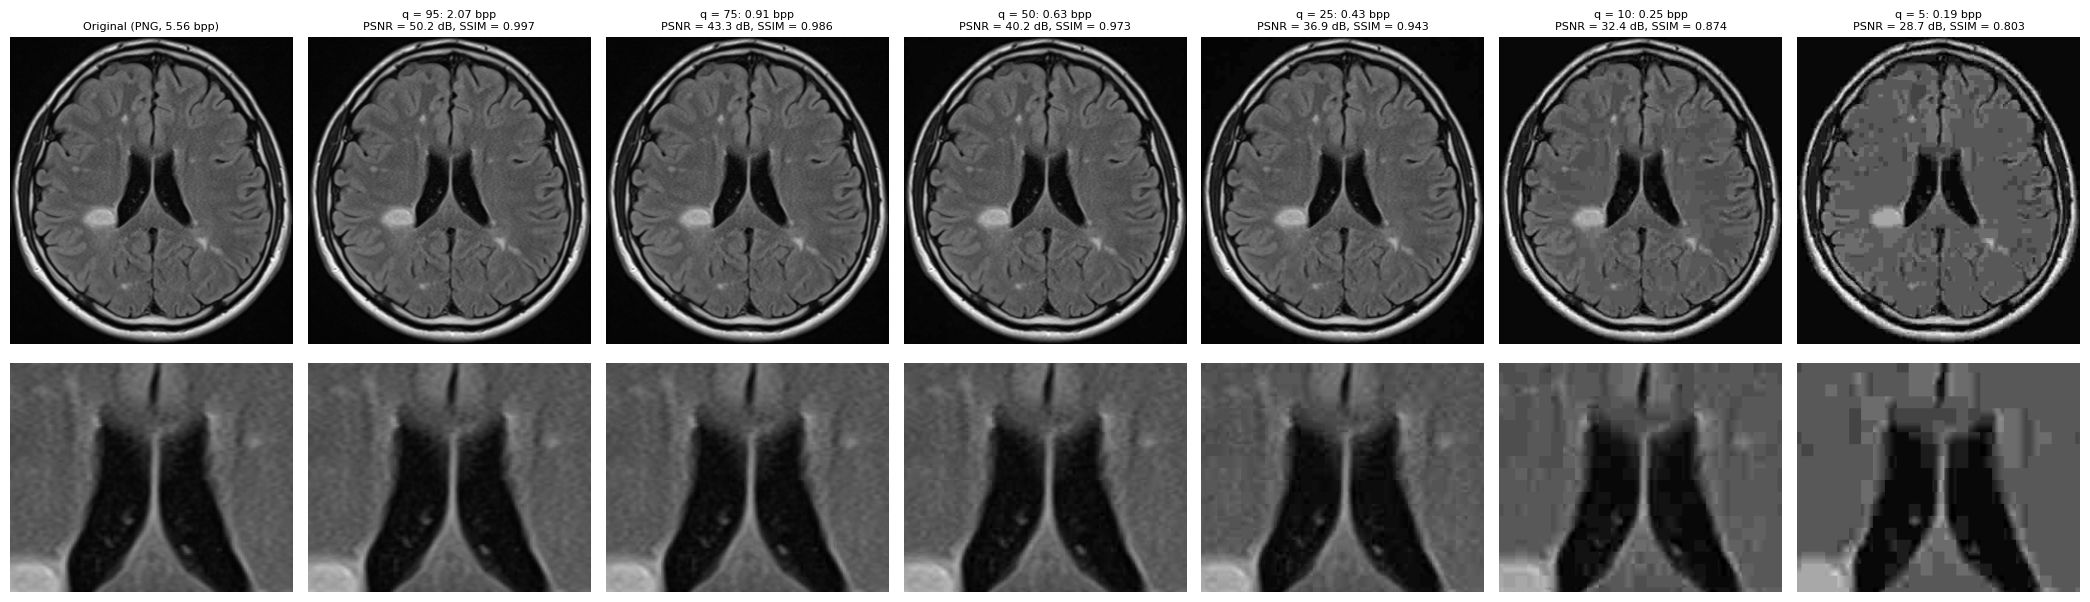

In [9]:
CALIDADES_JPEG = [95, 75, 50, 25, 10, 5]     # parámetro quality de Pillow

def comprimir_jpeg(img, calidad):
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=calidad)
    datos_jpg = buf.getvalue()
    rec = np.asarray(Image.open(io.BytesIO(datos_jpg)).convert("L"))
    return rec, 8 * len(datos_jpg) / img.size          # imagen reconstruida y bits por píxel

# Ejemplo: corte de MS con lesión periventricular evidente (usado en el notebook 03), con ampliación
EJEMPLO = DATA / "MS Axial_crop" / "A1 (505).png"
img = a_gris(EJEMPLO)
h, w = img.shape
zoom = (slice(int(0.30 * h), int(0.60 * h)), slice(int(0.30 * w), int(0.70 * w)))

fig, axs = plt.subplots(2, len(CALIDADES_JPEG) + 1, figsize=(3 * (len(CALIDADES_JPEG) + 1), 6.5))
axs[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); axs[0, 0].set_title(f"Original (PNG, {8 * EJEMPLO.stat().st_size / img.size:.2f} bpp)", fontsize=8)
axs[1, 0].imshow(img[zoom], cmap="gray", vmin=0, vmax=255)
for j, q in enumerate(CALIDADES_JPEG, start=1):
    rec, bpp = comprimir_jpeg(img, q)
    axs[0, j].imshow(rec, cmap="gray", vmin=0, vmax=255)
    axs[0, j].set_title(f"q = {q}: {bpp:.2f} bpp\nPSNR = {peak_signal_noise_ratio(img, rec, data_range=255):.1f} dB, "
                        f"SSIM = {structural_similarity(img, rec, data_range=255):.3f}", fontsize=8)
    axs[1, j].imshow(rec[zoom], cmap="gray", vmin=0, vmax=255)
for a in axs.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

&ensp; Se comprimió cada imagen original (8 bits, niveles de gris) en JPEG con Pillow, a seis calidades (`quality` = 95, 75, 50, 25, 10 y 5), y se volvió a decodificar. La tasa se mide en **bits por píxel (bpp)** del archivo JPEG real. En el corte de ejemplo (`A1 (505)`, 5,56 bpp en PNG) va de 2,07 bpp con q = 95 a 0,19 bpp con q = 5.

**Observación.** Hasta q = 25 (0,43 bpp, PSNR = 36,9 dB) la imagen es prácticamente indistinguible de la original, aun en la ampliación. Desde q = 10 aparecen los **bloques de 8 × 8 píxeles** típicos de JPEG: la sustancia blanca queda en parches planos, con saltos de intensidad entre bloques. La lesión periventricular grande sigue siendo visible en todos los niveles.

**Limitación.** El parámetro `quality` no es una escala lineal de tasa ni de calidad, y la tasa obtenida depende del contenido de cada imagen.

## 6.3 Compresión con wavelets

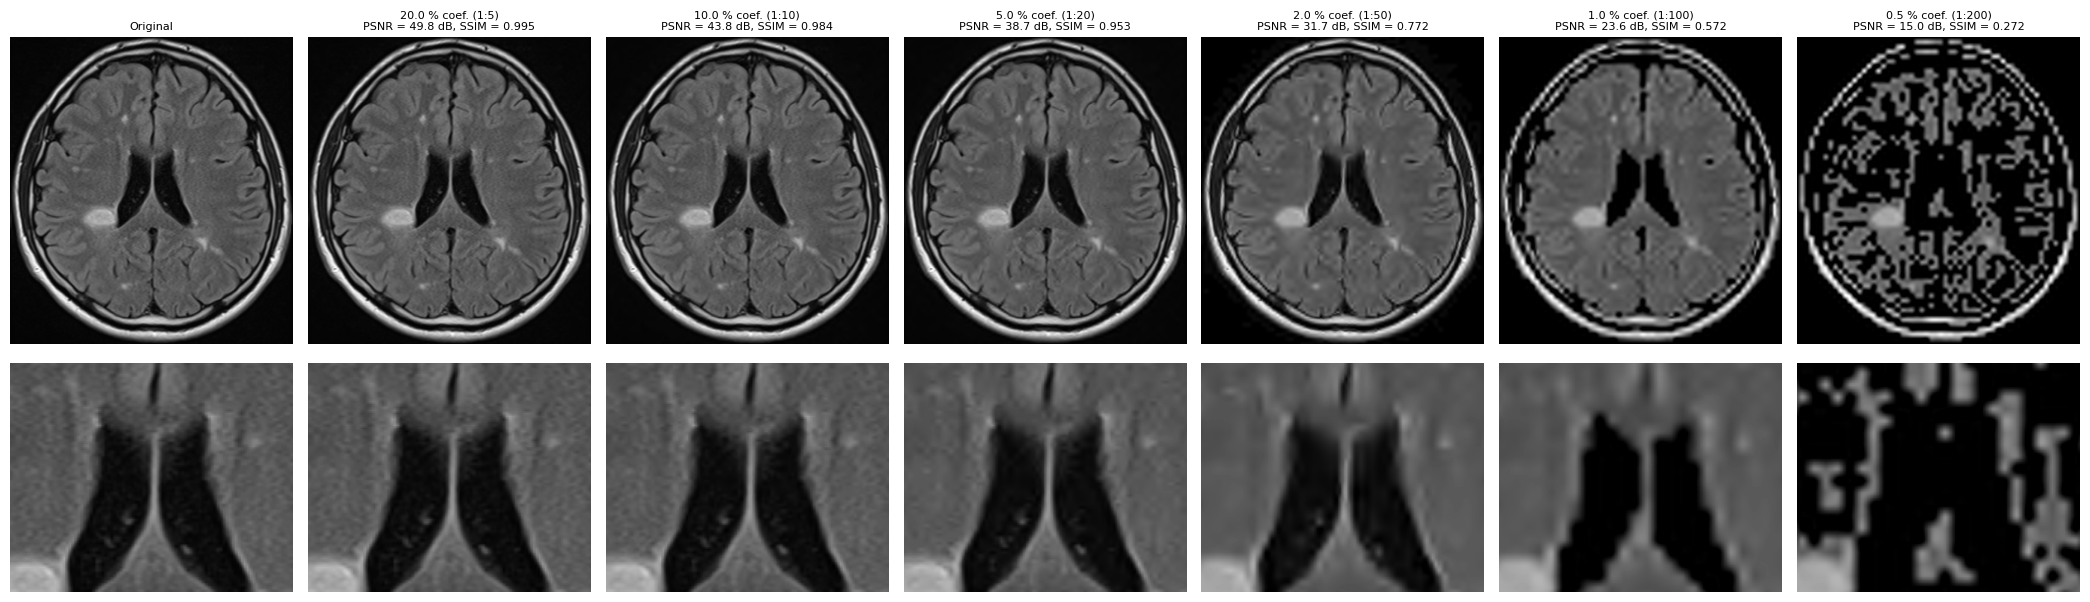

In [10]:
FRACCIONES_WAVELET = [0.20, 0.10, 0.05, 0.02, 0.01, 0.005]   # fracción de coeficientes que se conservan
WAVELET = "bior4.4"        # biortogonal 9/7 (CDF), la de JPEG 2000 con pérdida
NIVELES_WAVELET = 3

def comprimir_wavelet(img, fraccion, wavelet=WAVELET, nivel=NIVELES_WAVELET):
    coefs = pywt.wavedec2(img.astype(float), wavelet, level=nivel, mode="periodization")
    arr, cortes = pywt.coeffs_to_array(coefs)
    k = max(1, int(round(fraccion * arr.size)))
    umbral = np.partition(np.abs(arr).ravel(), -k)[-k]          # magnitud del k-ésimo coeficiente más grande
    arr[np.abs(arr) < umbral] = 0                                # umbral duro: el resto se anula
    rec = pywt.waverec2(pywt.array_to_coeffs(arr, cortes, output_format="wavedec2"), wavelet, mode="periodization")
    rec = rec[:img.shape[0], :img.shape[1]]
    return np.clip(np.round(rec), 0, 255).astype(np.uint8), np.count_nonzero(arr) / arr.size

fig, axs = plt.subplots(2, len(FRACCIONES_WAVELET) + 1, figsize=(3 * (len(FRACCIONES_WAVELET) + 1), 6.5))
axs[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); axs[0, 0].set_title("Original", fontsize=8)
axs[1, 0].imshow(img[zoom], cmap="gray", vmin=0, vmax=255)
for j, f in enumerate(FRACCIONES_WAVELET, start=1):
    rec, frac = comprimir_wavelet(img, f)
    axs[0, j].imshow(rec, cmap="gray", vmin=0, vmax=255)
    axs[0, j].set_title(f"{100 * frac:.1f} % coef. (1:{1 / frac:.0f})\nPSNR = {peak_signal_noise_ratio(img, rec, data_range=255):.1f} dB, "
                        f"SSIM = {structural_similarity(img, rec, data_range=255):.3f}", fontsize=8)
    axs[1, j].imshow(rec[zoom], cmap="gray", vmin=0, vmax=255)
for a in axs.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

&ensp; Se aplicó una transformada wavelet 2D con la wavelet biortogonal 9/7 (`bior4.4`, la de JPEG 2000 con pérdida) en 3 niveles. Se conservó una fracción de los coeficientes de mayor magnitud (20 %, 10 %, 5 %, 2 %, 1 % y 0,5 %), se anularon los demás (umbral duro), se reconstruyó y se redondeó a 8 bits. La tasa de compresión es **nominal** (1 / fracción: de 1:5 a 1:200), porque no se codificaron los coeficientes ni sus posiciones.

**Observación.** Hasta el 5 % (1:20) la imagen se ve bien. Al 2 % (1:50) se suaviza: se pierde la textura fina y los bordes quedan borrosos, pero sin bloques. Al 1 % (1:100) aparecen oscilaciones (*ringing*) alrededor de los bordes fuertes, como el cráneo y los ventrículos. **Al 0,5 % la imagen se destruye**: con 3 niveles, la banda de aproximación ocupa 1/64 ≈ 1,6 % de los coeficientes, así que conservar menos del 1,6 % obliga a descartar parte de la propia aproximación (las bajas frecuencias). A diferencia de JPEG, las wavelets degradan suavizando, no en bloques.

**Limitaciones.** Con tasas nominales, la comparación con JPEG favorece a las wavelets: un codificador real (cuantización y codificación de los coeficientes) necesitaría más bits. La fracción de coeficientes conservados se aplica a toda la imagen, incluido el fondo.

## 6.4 Pipeline completo sobre las imágenes comprimidas

In [11]:
def calidad_imagen(original, comprimida):
    return {"PSNR": peak_signal_noise_ratio(original, comprimida, data_range=255),
            "SSIM": structural_similarity(original, comprimida, data_range=255)}

def preprocesar_img(img):        # igual que preprocesar(ruta), pero recibe la imagen ya leída
    m = mascara_cerebral(img)
    z = a_tamano_comun(np.where(m, normalizar(img, m), 0))
    return z, a_tamano_comun(m, orden=0) > 0.5

def dice(a, b):
    s = a.sum() + b.sum()
    return 2 * np.logical_and(a, b).sum() / s if s else np.nan

# preprocesar_img tiene que dar lo mismo que preprocesar(ruta) sobre la imagen original
for ruta in muestra["Ruta"].iloc[:10]:
    z1, m1 = preprocesar(DATA / ruta)
    z2, m2 = preprocesar_img(a_gris(DATA / ruta))
    assert np.array_equal(z1, z2) and np.array_equal(m1, m2)
print("preprocesar_img coincide con preprocesar")

preprocesar_img coincide con preprocesar


In [12]:
# Para cada corte: pipeline sobre la original y sobre cada nivel de compresión. Se guardan la calidad de imagen,
# el Dice de la máscara y de la segmentación contra los de la original, y las características del notebook 04
def evaluar_corte(img, niveles_jpeg=CALIDADES_JPEG, niveles_wavelet=FRACCIONES_WAVELET):
    z0, m0 = preprocesar_img(img)
    s0 = umbral_adaptativo(z0, m0)
    filas = [{"Metodo": "Original", "Nivel": "-", "Tasa": np.nan, "PSNR": np.inf, "SSIM": 1.0,
              "Dice_mascara": 1.0, "Dice_seg": dice(s0, s0),
              **medidas_corte(m0, s0), **glcm_features(z0, region_profunda(m0, s0))}]
    variantes = [("JPEG", q, comprimir_jpeg, q) for q in niveles_jpeg] + \
                [("Wavelet", f, comprimir_wavelet, f) for f in niveles_wavelet]
    for metodo, nivel, funcion, param in variantes:
        rec, tasa = funcion(img, param)
        z, m = preprocesar_img(rec)
        s = umbral_adaptativo(z, m)
        filas.append({"Metodo": metodo, "Nivel": nivel, "Tasa": tasa, **calidad_imagen(img, rec),
                      "Dice_mascara": dice(m0, m), "Dice_seg": dice(s0, s),
                      **medidas_corte(m, s), **glcm_features(z, region_profunda(m, s))})
    return filas

CSV_COMP = Path("..") / "data" / "compresion_muestra.csv"
if CSV_COMP.exists():
    comp = pd.read_csv(CSV_COMP)
    print("Cargado desde", CSV_COMP)
else:
    t0 = time.time()
    filas = []
    for _, r in muestra.iterrows():
        for fila in evaluar_corte(a_gris(DATA / r["Ruta"])):
            filas.append({"Ruta": r["Ruta"], "Clase": r["Clase"], "Eje": r["Eje"], **fila})
    comp = pd.DataFrame(filas)
    comp.to_csv(CSV_COMP, index=False)
    print(f"Calculado en {(time.time() - t0) / 60:.1f} min y guardado en {CSV_COMP}")
comp["Nivel"] = comp["Nivel"].astype(str)
print(len(comp), "filas =", comp["Ruta"].nunique(), "cortes x", comp.groupby("Ruta").size().iloc[0], "versiones")

Calculado en 17.6 min y guardado en ..\data\compresion_muestra.csv
3900 filas = 300 cortes x 13 versiones


In [ ]:
# Comprobación: las características de la versión original coinciden con las del CSV del notebook 04
orig = comp[comp["Metodo"] == "Original"].set_index("Ruta")
ref = feat.set_index("Ruta").loc[orig.index]
cols = ["Area_cerebro_px", "N_regiones", "Area_lesion_px", "Area_rel"] + ["Contraste", "Homogeneidad", "Energia", "Correlacion", "Entropia"]
assert np.allclose(orig[cols].to_numpy(float), ref[cols].to_numpy(float), equal_nan=True)
print("La versión original reproduce el CSV del notebook 04")

La versión original reproduce el CSV del notebook 04


&ensp; Para cada uno de los **300 cortes de prueba** se corrió el pipeline completo del notebook 04 sobre la imagen original y sobre las 12 versiones comprimidas: máscara, normalización, segmentación, medidas y textura. Los 300 cortes son 75 por clase y eje, tomados de la partición 0 de grupos, que no se usó para fijar los umbrales de la regla en 6.1. Por cada versión se guardaron el PSNR y el SSIM contra la original, el Dice de la máscara y de la segmentación contra los de la original, y todas las características. En total son 3900 filas (300 cortes × 13 versiones), guardadas en `data/compresion_muestra.csv`. La primera corrida tarda unos 10 minutos; después se carga el CSV.

**Comprobaciones.** `preprocesar_img`, que recibe la imagen ya leída para poder pasarle la comprimida, da exactamente lo mismo que `preprocesar(ruta)`. Las características de la versión original reproducen las del CSV del notebook 04.

**Limitación.** Por el costo de repetir el pipeline 13 veces por corte, se usó una muestra de 300 cortes y no el dataset completo.

## 6.5 Calidad de imagen

In [14]:
# Tasa de compresión respecto de la imagen sin comprimir a 8 bits por píxel. En JPEG es real (tamaño del archivo);
# en wavelets es nominal (1 / fracción de coeficientes), porque no se codificaron los coeficientes.
cmp = comp[comp["Metodo"] != "Original"].copy()
cmp["Compresion"] = np.where(cmp["Metodo"] == "JPEG", 8 / cmp["Tasa"], 1 / cmp["Tasa"])
calidad = (cmp.groupby(["Metodo", "Nivel"], sort=False)
              .agg(Compresion=("Compresion", "median"), PSNR=("PSNR", "median"), SSIM=("SSIM", "median"),
                   PSNR_P10=("PSNR", lambda v: np.percentile(v, 10)), SSIM_P10=("SSIM", lambda v: np.percentile(v, 10))))
png_bpp = np.median([8 * (DATA / r).stat().st_size / a_gris(DATA / r).size for r in muestra["Ruta"]])
print(f"PNG original (sin pérdida): mediana {png_bpp:.2f} bpp -> compresión 1:{8 / png_bpp:.1f}")
calidad.round(3)

PNG original (sin pérdida): mediana 4.42 bpp -> compresión 1:1.8


Compresion    PSNR   SSIM  PSNR_P10  SSIM_P10
Metodo  Nivel                                               
JPEG    95          5.075  52.823  0.998    51.656     0.997
        75         11.799  46.312  0.990    44.984     0.988
        50         17.041  42.894  0.980    41.588     0.975
        25         24.445  39.053  0.956    37.727     0.944
        10         39.145  33.734  0.882    32.611     0.847
        5          53.083  29.607  0.782    28.456     0.610
Wavelet 0.2         5.000  55.223  0.998    52.183     0.997
        0.1        10.000  50.122  0.995    45.651     0.989
        0.05       20.000  44.231  0.983    39.789     0.961
        0.02       50.000  35.248  0.907    32.884     0.822
        0.01      100.001  27.664  0.565    25.156     0.512
        0.005     200.000  18.716  0.295    15.319     0.223

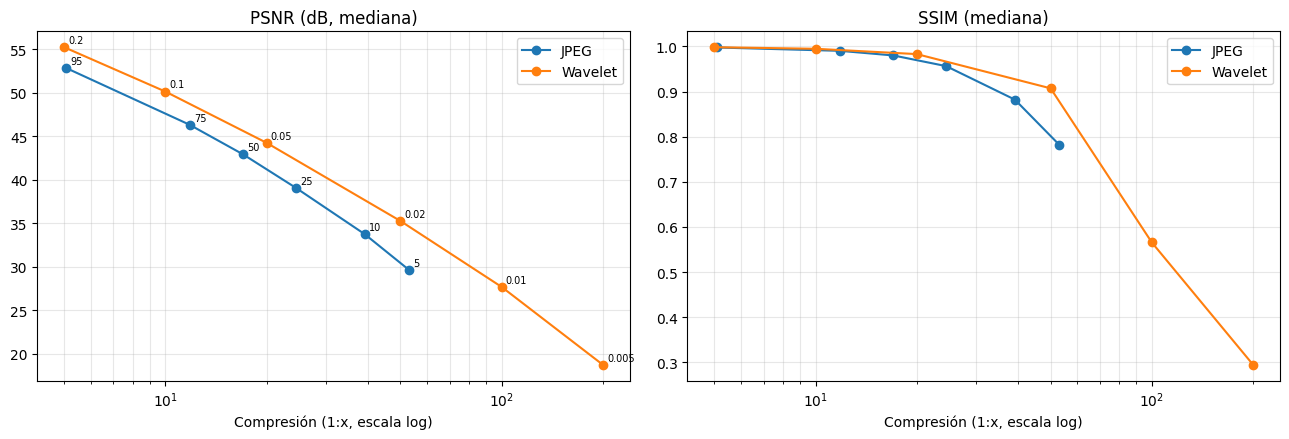

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for metodo, color in [("JPEG", "tab:blue"), ("Wavelet", "tab:orange")]:
    d = calidad.loc[metodo]
    axs[0].plot(d["Compresion"], d["PSNR"], "o-", color=color, label=metodo)
    axs[1].plot(d["Compresion"], d["SSIM"], "o-", color=color, label=metodo)
    for nivel, r in d.iterrows():
        axs[0].annotate(nivel, (r["Compresion"], r["PSNR"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
for ax, t in zip(axs, ["PSNR (dB, mediana)", "SSIM (mediana)"]):
    ax.set_xscale("log"); ax.set_xlabel("Compresión (1:x, escala log)"); ax.set_title(t)
    ax.grid(True, alpha=0.3, which="both"); ax.legend()
plt.tight_layout()
plt.show()

&ensp; La compresión se mide respecto de la imagen sin comprimir a 8 bpp. Como referencia, los PNG originales (sin pérdida) ocupan una mediana de **4,42 bpp (1:1,8)**.

| Método | Nivel | Compresión (mediana) | PSNR (dB) | SSIM |
|---|---|---|---|---|
| JPEG | q = 95 | 1:5,1 | 52,8 | 0,998 |
| JPEG | q = 75 | 1:11,8 | 46,3 | 0,990 |
| JPEG | q = 50 | 1:17,0 | 42,9 | 0,980 |
| JPEG | q = 25 | 1:24,4 | 39,1 | 0,956 |
| JPEG | q = 10 | 1:39,1 | 33,7 | 0,882 |
| JPEG | q = 5 | 1:53,1 | 29,6 | 0,782 |
| Wavelet | 20 % | 1:5 | 55,2 | 0,998 |
| Wavelet | 10 % | 1:10 | 50,1 | 0,995 |
| Wavelet | 5 % | 1:20 | 44,2 | 0,983 |
| Wavelet | 2 % | 1:50 | 35,2 | 0,907 |
| Wavelet | 1 % | 1:100 | 27,7 | 0,565 |
| Wavelet | 0,5 % | 1:200 | 18,7 | 0,295 |

**Resultados.**
- Las dos métricas caen de forma monótona con la compresión. Hasta 1:24 en JPEG y 1:20 en wavelets, el PSNR se mantiene por encima de 39 dB y el SSIM por encima de 0,95.
- A igual tasa nominal, las wavelets dan mayor PSNR y SSIM que JPEG hasta 1:20 (44,2 dB a 1:20 contra 42,9 dB de JPEG a 1:17), pero caen más rápido después: SSIM de 0,565 a 1:100, por la pérdida de la banda de aproximación. Esta comparación favorece a las wavelets, porque su tasa es nominal (6.3).
- Los percentiles 10 están cerca de las medianas salvo en los niveles extremos (SSIM P10 = 0,610 en JPEG q = 5), donde algunas imágenes se degradan mucho más que otras.

**Limitaciones.** El PSNR y el SSIM se calculan sobre la imagen completa, incluido el fondo, que se comprime casi sin error y mejora las métricas. Una buena calidad global no garantiza que se conserven detalles chicos como las lesiones, y por eso en 6.6 y 6.7 se evalúa el pipeline directamente.

## 6.6 Efecto sobre la máscara y la segmentación

In [16]:
# Dice de la máscara y de la segmentación contra la versión original del mismo corte. El Dice de la segmentación
# solo se calcula cuando la original o la comprimida tienen alguna región. "Detección igual": la comprimida tiene
# alguna región si y solo si la original la tiene.
base = comp[comp["Metodo"] == "Original"].set_index("Ruta")
cmp["Area_rel_0"] = cmp["Ruta"].map(base["Area_rel"])
cmp["N_regiones_0"] = cmp["Ruta"].map(base["N_regiones"])
cmp["Deteccion_igual"] = (cmp["N_regiones"] > 0) == (cmp["N_regiones_0"] > 0)
cmp["Dif_Area_rel"] = cmp["Area_rel"] - cmp["Area_rel_0"]
cmp["Dif_N_regiones"] = cmp["N_regiones"] - cmp["N_regiones_0"]

seg = (cmp.groupby(["Metodo", "Nivel"], sort=False)
          .agg(Compresion=("Compresion", "median"),
               Dice_mascara=("Dice_mascara", "median"),
               Dice_seg_mediana=("Dice_seg", "median"), Dice_seg_media=("Dice_seg", "mean"),
               Deteccion_igual=("Deteccion_igual", "mean"),
               Dif_Area_rel_media=("Dif_Area_rel", "mean"), Dif_N_regiones_media=("Dif_N_regiones", "mean")))
print("Cortes con alguna región en la original:", (base["N_regiones"] > 0).sum(), "de", len(base))
seg.round(3)

Cortes con alguna región en la original: 143 de 300


Compresion  Dice_mascara  Dice_seg_mediana  Dice_seg_media  \
Metodo  Nivel                                                               
JPEG    95          5.075         0.999             0.994           0.946   
        75         11.799         0.999             0.972           0.883   
        50         17.041         0.998             0.946           0.855   
        25         24.445         0.997             0.896           0.726   
        10         39.145         0.995             0.660           0.519   
        5          53.083         0.992             0.074           0.283   
Wavelet 0.2         5.000         1.000             0.996           0.972   
        0.1        10.000         0.999             0.981           0.884   
        0.05       20.000         0.999             0.928           0.786   
        0.02       50.000         0.995             0.717           0.575   
        0.01      100.001         0.986             0.542           0.452   
        0.005     200.000         0.955             0.427           0.376   

               Deteccion_igual  Dif_Area_rel_media  Dif_N_regiones_media  
Metodo  Nivel                                                             
JPEG    95               0.987              -0.000                -0.003  
        75               0.967              -0.000                 0.000  
        50               0.967              -0.000                -0.030  
        25               0.913              -0.001                -0.090  
        10               0.833               0.000                 0.060  
        5                0.713               0.011                 1.010  
Wavelet 0.2              0.997               0.000                 0.020  
        0.1              0.967               0.000                 0.007  
        0.05             0.930               0.001                 0.093  
        0.02             0.843               0.003                 0.417  
        0.01             0.780               0.005                 0.780  
        0.005            0.757               0.001                -0.310

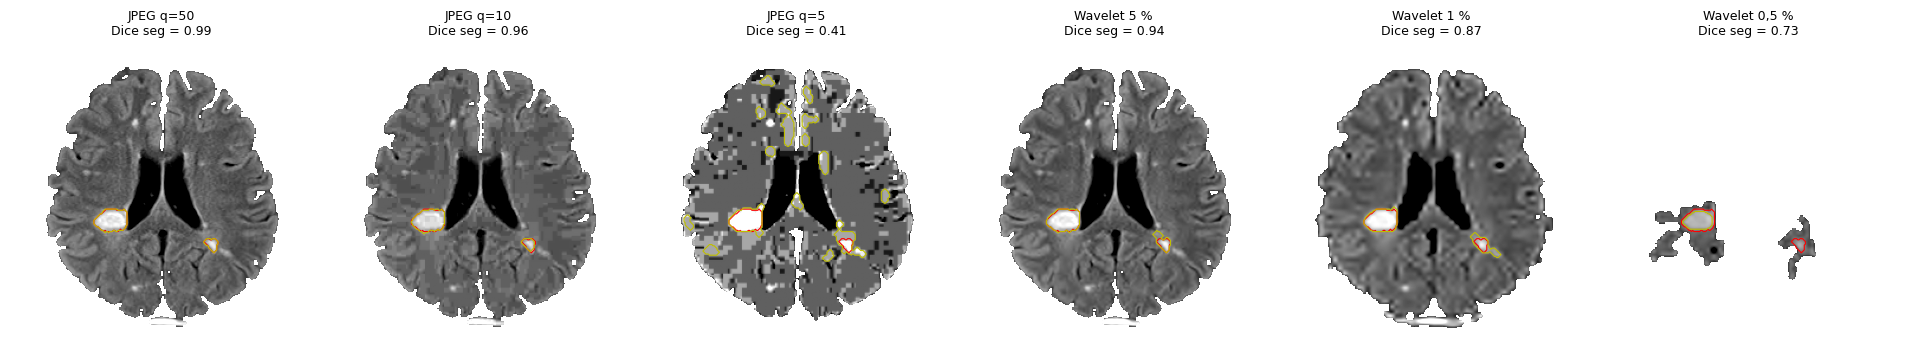

In [17]:
# Ejemplo visual: segmentación de A1 (505) a distintos niveles (rojo: original; amarillo: comprimida)
z0, m0 = preprocesar_img(img)
s0 = umbral_adaptativo(z0, m0)
versiones = [("JPEG q=50", comprimir_jpeg(img, 50)[0]), ("JPEG q=10", comprimir_jpeg(img, 10)[0]),
             ("JPEG q=5", comprimir_jpeg(img, 5)[0]), ("Wavelet 5 %", comprimir_wavelet(img, 0.05)[0]),
             ("Wavelet 1 %", comprimir_wavelet(img, 0.01)[0]), ("Wavelet 0,5 %", comprimir_wavelet(img, 0.005)[0])]
fig, axs = plt.subplots(1, len(versiones), figsize=(3.2 * len(versiones), 3.6))
for ax, (titulo, rec) in zip(axs, versiones):
    z, m = preprocesar_img(rec)
    s = umbral_adaptativo(z, m)
    ax.imshow(np.where(m, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    if s0.any(): ax.contour(s0.astype(float), levels=[0.5], colors="r", linewidths=0.8)
    if s.any(): ax.contour(s.astype(float), levels=[0.5], colors="y", linewidths=0.8)
    ax.set_title(f"{titulo}\nDice seg = {dice(s0, s):.2f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

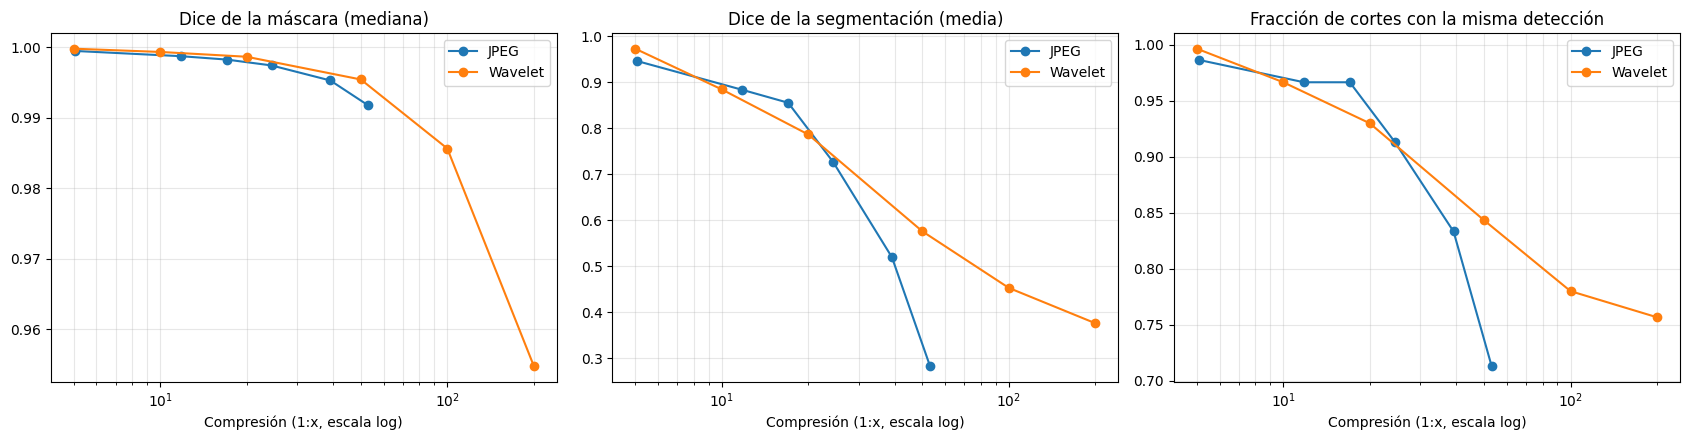

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for metodo, color in [("JPEG", "tab:blue"), ("Wavelet", "tab:orange")]:
    d = seg.loc[metodo]
    axs[0].plot(d["Compresion"], d["Dice_mascara"], "o-", color=color, label=metodo)
    axs[1].plot(d["Compresion"], d["Dice_seg_media"], "o-", color=color, label=metodo)
    axs[2].plot(d["Compresion"], d["Deteccion_igual"], "o-", color=color, label=metodo)
for ax, t in zip(axs, ["Dice de la máscara (mediana)", "Dice de la segmentación (media)", "Fracción de cortes con la misma detección"]):
    ax.set_xscale("log"); ax.set_xlabel("Compresión (1:x, escala log)"); ax.set_title(t)
    ax.grid(True, alpha=0.3, which="both"); ax.legend()
plt.tight_layout()
plt.show()

&ensp; La pregunta de fondo es si **la segmentación sobrevive a la compresión**. Como no hay ground truth, se compara cada versión comprimida con la segmentación de la original del mismo corte. De los 300 cortes, 143 tienen alguna región en la original.

| Método | Nivel | Compresión | Dice máscara | Dice seg. (media) | Dice seg. (mediana) | Misma detección | Δ N_regiones (media) |
|---|---|---|---|---|---|---|---|
| JPEG | q = 95 | 1:5,1 | 0,999 | 0,946 | 0,994 | 98,7 % | −0,00 |
| JPEG | q = 50 | 1:17,0 | 0,998 | 0,855 | 0,946 | 96,7 % | −0,03 |
| JPEG | q = 25 | 1:24,4 | 0,997 | 0,726 | 0,896 | 91,3 % | −0,09 |
| JPEG | q = 10 | 1:39,1 | 0,995 | 0,519 | 0,660 | 83,3 % | +0,06 |
| JPEG | q = 5 | 1:53,1 | 0,992 | 0,283 | 0,074 | 71,3 % | +1,01 |
| Wavelet | 10 % | 1:10 | 0,999 | 0,884 | 0,981 | 96,7 % | +0,01 |
| Wavelet | 5 % | 1:20 | 0,999 | 0,786 | 0,928 | 93,0 % | +0,09 |
| Wavelet | 2 % | 1:50 | 0,995 | 0,575 | 0,717 | 84,3 % | +0,42 |
| Wavelet | 1 % | 1:100 | 0,986 | 0,452 | 0,542 | 78,0 % | +0,78 |
| Wavelet | 0,5 % | 1:200 | 0,955 | 0,376 | 0,427 | 75,7 % | −0,31 |

**Resultados.**
- **La máscara cerebral es muy robusta**: Dice ≥ 0,98 en todos los niveles salvo wavelet 0,5 %. Otsu y la morfología trabajan sobre el contraste grueso cerebro/fondo, que la compresión conserva.
- **La segmentación es mucho más sensible.** Hasta JPEG q = 25 (1:24) y wavelet 5 % (1:20), la mediana del Dice se mantiene en ≥ 0,89 y la detección coincide en ≥ 91 % de los cortes. Desde ahí cae rápido.
- La media del Dice es bastante menor que la mediana: hay cortes con regiones chicas, cerca del área mínima de 50 px, que aparecen o desaparecen por completo (Dice = 0), mientras que las lesiones grandes se conservan. En el ejemplo `A1 (505)`, la lesión grande da Dice 0,99 con JPEG q = 50 y 0,96 con q = 10.
- **Con compresión fuerte aparecen falsos positivos**: `N_regiones` sube en promedio 1,01 regiones por corte con JPEG q = 5 y 0,78 con wavelet 1 %. Los bloques de JPEG y el *ringing* de las wavelets generan manchas que el umbral adaptativo toma como lesiones (se ve en el ejemplo con q = 5). Con wavelet 0,5 % el promedio baja porque la máscara se rompe (6.3) y hay menos cerebro donde segmentar, no porque mejore.

**Limitaciones.** «Sobrevivir» significa acá coincidir con la segmentación de la original, que tampoco está validada: el Dice no dice si la segmentación es correcta, sino si es estable. La muestra es de 300 cortes, con solo 143 que tienen alguna región.

## 6.7 Efecto sobre la clasificación

In [19]:
# La regla (umbrales fijados con imágenes originales en 6.1) se aplica a las características de cada versión
comp["y"] = (comp["Clase"] == "MS").astype(int)
cols_regla = [c for c, _ in REGLA]
ok_feat = comp[cols_regla].notna().all(axis=1)
comp["pred"] = np.nan
comp.loc[ok_feat, "pred"] = aplicar_regla(comp[ok_feat], umbrales).astype(float)
p0 = comp[comp["Metodo"] == "Original"].set_index("Ruta")["pred"]
comp["Cambia_prediccion"] = comp["pred"] != comp["Ruta"].map(p0)

filas = []
for (metodo, nivel), d in comp.groupby(["Metodo", "Nivel"], sort=False):
    d = d.dropna(subset=["pred"])
    filas.append({"Metodo": metodo, "Nivel": nivel, "n": len(d), **metricas(d["y"].to_numpy(), d["pred"].to_numpy()),
                  "% predicciones que cambian": 100 * d["Cambia_prediccion"].mean()})
clas = pd.DataFrame(filas).set_index(["Metodo", "Nivel"])
clas["Compresion"] = calidad["Compresion"].reindex(clas.index)
clas[["Compresion", "n", "Sensibilidad", "Especificidad", "Exactitud balanceada", "% predicciones que cambian"]].round(3)

Compresion    n  Sensibilidad  Especificidad  \
Metodo   Nivel                                                 
Original -             NaN  300         0.580          0.913   
JPEG     95          5.075  300         0.600          0.913   
         75         11.799  300         0.600          0.927   
         50         17.041  300         0.613          0.900   
         25         24.445  300         0.587          0.860   
         10         39.145  300         0.547          0.827   
         5          53.083  296         0.514          0.727   
Wavelet  0.2         5.000  300         0.587          0.913   
         0.1        10.000  300         0.587          0.913   
         0.05       20.000  300         0.573          0.880   
         0.02       50.000  300         0.527          0.867   
         0.01      100.001  300         0.600          0.773   
         0.005     200.000  266         0.447          0.874   

                Exactitud balanceada  % predicciones que cambian  
Metodo   Nivel                                                    
Original -                     0.747                       0.000  
JPEG     95                    0.757                       2.333  
         75                    0.763                       3.000  
         50                    0.757                       4.333  
         25                    0.723                       7.000  
         10                    0.687                      16.000  
         5                     0.620                      30.405  
Wavelet  0.2                   0.750                       1.000  
         0.1                   0.750                       1.000  
         0.05                  0.727                       6.000  
         0.02                  0.697                      15.667  
         0.01                  0.687                      22.667  
         0.005                 0.661                      18.421

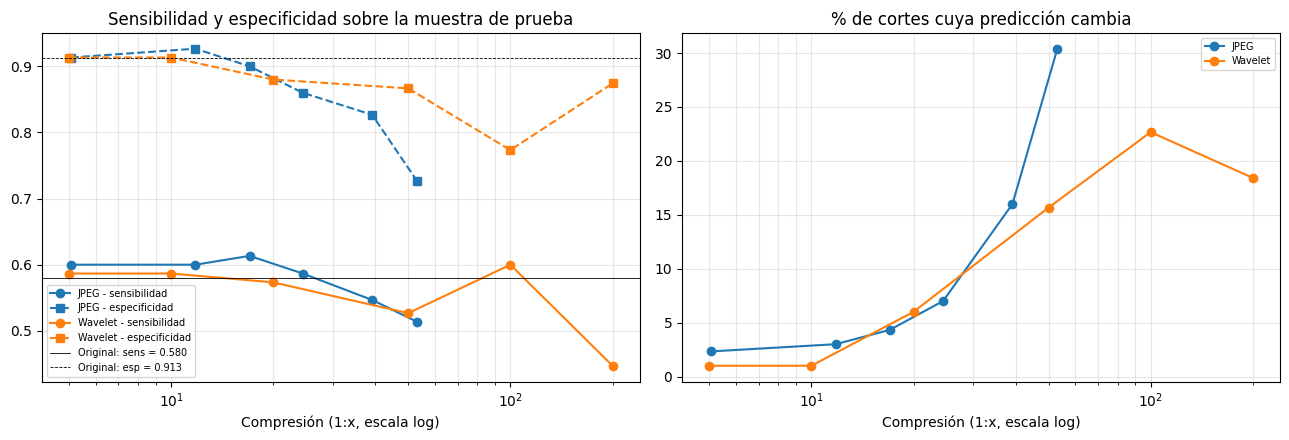

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
eb0 = clas.loc[("Original", "-"), "Exactitud balanceada"]
for metodo, color in [("JPEG", "tab:blue"), ("Wavelet", "tab:orange")]:
    d = clas.loc[metodo]
    axs[0].plot(d["Compresion"], d["Sensibilidad"], "o-", color=color, label=f"{metodo} - sensibilidad")
    axs[0].plot(d["Compresion"], d["Especificidad"], "s--", color=color, label=f"{metodo} - especificidad")
    axs[1].plot(d["Compresion"], d["% predicciones que cambian"], "o-", color=color, label=metodo)
o = clas.loc[("Original", "-")]
axs[0].axhline(o["Sensibilidad"], color="k", ls="-", lw=0.6, label=f"Original: sens = {o['Sensibilidad']:.3f}")
axs[0].axhline(o["Especificidad"], color="k", ls="--", lw=0.6, label=f"Original: esp = {o['Especificidad']:.3f}")
for ax, t in zip(axs, ["Sensibilidad y especificidad sobre la muestra de prueba", "% de cortes cuya predicción cambia"]):
    ax.set_xscale("log"); ax.set_xlabel("Compresión (1:x, escala log)"); ax.set_title(t)
    ax.grid(True, alpha=0.3, which="both"); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [21]:
# ¿Qué parte de la regla cambia con la compresión? Fracción de cortes en los que se dispara cada característica
# (con los umbrales de 6.1) y mediana de la entropía, por clase
for c, sentido in REGLA:
    u = comp["Eje"].map({e: umbrales[(e, c)] for e in ["Axial", "Sagital"]})
    comp[f"Supera_{c}"] = comp[c] > u if sentido == ">" else comp[c] < u
desglose = (comp.groupby(["Metodo", "Nivel", "Clase"], sort=False)
                .agg(Supera_Area_rel=("Supera_Area_rel", "mean"), Supera_Entropia=("Supera_Entropia", "mean"),
                     Entropia_mediana=("Entropia", "median"))
                .unstack("Clase"))
desglose.round(3)

Supera_Area_rel        Supera_Entropia        Entropia_mediana  \
Clase                  Control     MS         Control     MS          Control   
Metodo   Nivel                                                                  
Original -               0.040  0.433           0.047  0.373            5.685   
JPEG     95              0.033  0.440           0.053  0.387            5.688   
         75              0.033  0.440           0.040  0.387            5.692   
         50              0.027  0.440           0.073  0.387            5.714   
         25              0.047  0.413           0.093  0.373            5.729   
         10              0.113  0.447           0.067  0.180            5.498   
         5               0.273  0.507           0.000  0.000            4.421   
Wavelet  0.2             0.033  0.433           0.053  0.380            5.677   
         0.1             0.047  0.420           0.040  0.367            5.674   
         0.05            0.053  0.460           0.067  0.287            5.651   
         0.02            0.127  0.513           0.007  0.067            5.533   
         0.01            0.227  0.600           0.000  0.000            5.361   
         0.005           0.120  0.420           0.000  0.007            5.253   

                       
Clase              MS  
Metodo   Nivel         
Original -      5.878  
JPEG     95     5.867  
         75     5.896  
         50     5.904  
         25     5.881  
         10     5.544  
         5      4.292  
Wavelet  0.2    5.880  
         0.1    5.858  
         0.05   5.802  
         0.02   5.611  
         0.01   5.409  
         0.005  5.292

&ensp; La regla del notebook 05 (**MS si `Area_rel` o entropía superan el percentil 95 de los controles de su eje**) se aplicó a cada versión con umbrales fijados en 6.1 a partir de las **imágenes originales** de 2227 cortes, sin recalcularlos. Esto simula una regla calibrada con imágenes de calidad diagnóstica que después recibe imágenes comprimidas.

| Método | Nivel | Compresión | Sensibilidad | Especificidad | Exactitud balanceada | Predicciones que cambian |
|---|---|---|---|---|---|---|
| Original | — | — | 0,580 | 0,913 | 0,747 | — |
| JPEG | q = 95 | 1:5,1 | 0,600 | 0,913 | 0,757 | 2,3 % |
| JPEG | q = 50 | 1:17,0 | 0,613 | 0,900 | 0,757 | 4,3 % |
| JPEG | q = 25 | 1:24,4 | 0,587 | 0,860 | 0,723 | 7,0 % |
| JPEG | q = 10 | 1:39,1 | 0,547 | 0,827 | 0,687 | 16,0 % |
| JPEG | q = 5 | 1:53,1 | 0,514 | 0,727 | 0,620 | 30,4 % |
| Wavelet | 10 % | 1:10 | 0,587 | 0,913 | 0,750 | 1,0 % |
| Wavelet | 5 % | 1:20 | 0,573 | 0,880 | 0,727 | 6,0 % |
| Wavelet | 2 % | 1:50 | 0,527 | 0,867 | 0,697 | 15,7 % |
| Wavelet | 1 % | 1:100 | 0,600 | 0,773 | 0,687 | 22,7 % |
| Wavelet | 0,5 % | 1:200 | 0,447 | 0,874 | 0,661 | 18,4 % |

&ensp; Sobre la imagen original, la regla da en esta muestra una sensibilidad de 0,580 y una especificidad de 0,913, parecidas a las de la validación del notebook 05 (0,531 y 0,903). Con 150 cortes por clase, cada proporción tiene una incertidumbre del orden de ±0,05–0,08, así que las diferencias menores no deben interpretarse.

**Resultados.**
- **La clasificación sobrevive hasta JPEG q = 50 (1:17) y wavelet 10 % (1:10)**: la sensibilidad y la especificidad quedan prácticamente iguales a las de la original, y cambia la predicción de menos del 5 % de los cortes. Con JPEG q = 25 y wavelet 5 % (1:20–1:24) empieza a bajar la especificidad (0,86–0,88) y cambia el 6–7 % de las predicciones.
- Con compresión más fuerte, el error es **sistemático**, y la tabla de desglose muestra por qué. La compresión actúa en sentidos opuestos sobre las dos partes de la regla:
  - **La entropía baja** en las dos clases (mediana de 5,69 a 4,42 en Control y de 5,88 a 4,29 en MS con JPEG q = 5), porque los bloques de JPEG y el suavizado de las wavelets aplanan la textura. Esa parte de la regla deja de dispararse: con JPEG q = 5 y wavelet 1 %, ningún corte supera el umbral de entropía.
  - **La segmentación marca más**, por los falsos positivos de 6.6. Los controles que superan el umbral de `Area_rel` pasan del 4,0 % al 27,3 % con JPEG q = 5 y al 22,7 % con wavelet 1 %.
  - El resultado es una **caída de la especificidad** (hasta 0,727 con JPEG q = 5) y una sensibilidad que se mantiene solo en apariencia, porque ahora la sostienen los artefactos de la segmentación en lugar de la textura. Con wavelet 0,5 % cae también la sensibilidad (0,447), y 34 cortes quedan sin predicción porque la máscara se rompe y la región profunda no alcanza los 200 px.

**Limitaciones.** Se evaluó una sola regla, con umbrales de una sola partición, sobre 300 cortes. Los umbrales se fijaron con imágenes originales: si se fijaran con imágenes comprimidas, la regla podría recuperar parte del rendimiento, pero dejaría de ser la misma regla.